# Vertical Dust Settling in a Protoplanetary Disk

This notebook builds a simple Python model of how dust grains of different sizes settle toward the midplane of a gaseous disk. It uses only **NumPy** and **Matplotlib** and runs entirely within this notebook.

The model follows a fixed disk column at 1 AU. The gas does not evolve with time, dust does not affect the gas, and there is no turbulent mixing or radial motion.

## Physical model

In vertical hydrostatic equilibrium, the gas density has a Gaussian profile:

$$\rho_g(z)=\frac{\Sigma_g}{\sqrt{2\pi}H}\exp\!\left(-\frac{z^2}{2H^2}\right),$$

Here, $H=0.05r$ is the pressure scale height and $\Sigma_g=889(r/\mathrm{AU})^{-0.5}\ \mathrm{g\,cm^{-2}}$. The gas sound speed is $c_s=H\Omega$, and the mean thermal speed is $v_{th}=\sqrt{8/\pi}\,c_s$.

In the Epstein drag regime, the particle stopping time is

$$t_{stop}=\frac{\rho_\bullet a}{\rho_g v_{th}},$$

For small Stokes numbers, the terminal settling velocity is approximated by

$$\frac{dz}{dt}=-\Omega^2t_{stop}z.$$

This terminal-velocity approximation is valid when $\mathrm{St}=\Omega t_{stop}\ll1$; the notebook checks that this condition holds for the chosen parameters. We integrate the logarithm of $z/H$ rather than $z/H$ itself, which keeps the height positive throughout the calculation.

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# CGS units
G = 6.67430e-8                 # gravitational constant, cm^3 g^-1 s^-2
M_sun = 1.98847e33             # solar mass, g
AU = 1.495978707e13            # astronomical unit, cm
YEAR = 365.25 * 24 * 60 * 60   # year in seconds

# Disk and simulation parameters
r_AU = 1.0
r = r_AU * AU                   # distance from the star, cm
aspect_ratio = 0.05
Sigma_1AU = 889.0               # g/cm^2 at 1 AU -- calculated from former simulations
Sigma = Sigma_1AU * r_AU**(-0.5)
rho_s = 1.6                     # grain internal density, g/cm^3 (1.6 is a canonical value for silicate grains)
z0_over_H = 1.0                 # initial dust layer scale height relative to the gas scale height
grain_radii_cm = np.array([0.01, 0.1, 1.0])  # cm: 0.1, 1, and 10 mm

Omega = np.sqrt(G * M_sun / r**3)  # angular Keplerian frequency, s^-1
H = aspect_ratio * r               # scale height, cm
c_s = H * Omega                    # sound speed, cm/s
v_th = np.sqrt(8.0 / np.pi) * c_s  # mean thermal speed calculated from the sound speed, cm/s
rho_mid = Sigma / (np.sqrt(2.0 * np.pi) * H)    # midplane gas density, g/cm^3

t_end_years = 10000.0               # total simulation time in years
dt_years = 0.1                      # timestep in years
time_years = np.arange(0.0, t_end_years + dt_years, dt_years)   # array of time points in years
dt = dt_years * YEAR                # timestep in seconds

print(f"Omega = {Omega:.3e} 1/s; H = {H / AU:.3f} AU")
print(f"Midplane gas density: {rho_mid:.3e} g/cm^3")
print(f"Duration: {t_end_years:g} years; timestep: {dt_years:g} years")

Omega = 1.991e-07 1/s; H = 0.050 AU
Midplane gas density: 4.742e-10 g/cm^3
Duration: 10000 years; timestep: 0.1 years


## Drag and settling code

All grains start at the same initial height. For small Stokes number, the vertical settling velocity is

$$\frac{dz}{dt}=-\Omega^2 t_{\rm stop}z.$$

At the fixed radius used here, the gas scale height $H$ is constant. Define the dimensionless height $h=z/H$. Then

$$\frac{dh}{dt}=-\Omega^2 t_{\rm stop}h.$$

The code integrates $x=\ln h=\ln(z/H)$ instead of $h$. By the chain rule,

$$\frac{dx}{dt}=\frac{1}{h}\frac{dh}{dt}=-\Omega^2 t_{\rm stop}.$$

This is the quantity returned by `dlog_height_dt`: `log_height` is $x$, and `np.exp(log_height)` recovers $z/H$. Integrating the logarithm keeps the computed height positive. The rate has units of $1/\mathrm{s}$ because $\Omega^2$ has units of $1/\mathrm{s}^2$ and $t_{\rm stop}$ has units of seconds.

The RK4 (fourth-order Runge–Kutta) method advances this equation in time. Grain sizes are stored in a NumPy array, so all three trajectories are computed at each timestep.

In [ ]:
def stopping_time(z_over_H, grain_radius_cm):
    """Epstein stopping time in seconds; z_over_H may be an array."""
    # Stopping time means the characteristic time for a dust grain to adjust its velocity to the gas velocity
    rho_g = rho_mid * np.exp(-0.5 * np.asarray(z_over_H) ** 2)
    return rho_s * grain_radius_cm / (rho_g * v_th)


def dlog_height_dt(log_height, grain_radius_cm):
    """d ln(z/H)/dt under the terminal-settling approximation, in 1/s."""
    z_over_H = np.exp(log_height)
    t_stop = stopping_time(z_over_H, grain_radius_cm)
    return -(Omega**2) * t_stop


log_height = np.full(len(grain_radii_cm), np.log(z0_over_H))
log_height_history = np.empty((len(time_years), len(grain_radii_cm)))
log_height_history[0] = log_height

for i in range(len(time_years) - 1):
    k1 = dlog_height_dt(log_height, grain_radii_cm)
    k2 = dlog_height_dt(log_height + 0.5 * dt * k1, grain_radii_cm)
    k3 = dlog_height_dt(log_height + 0.5 * dt * k2, grain_radii_cm)
    k4 = dlog_height_dt(log_height + dt * k3, grain_radii_cm)
    log_height = log_height + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    log_height_history[i + 1] = log_height

z_over_H = np.exp(log_height_history)
rho_g_history = rho_mid * np.exp(-0.5 * z_over_H**2)
stokes_history = (
    rho_s * grain_radii_cm[None, :] / (rho_g_history * v_th) * Omega
)

print("Maximum Stokes numbers:", np.max(stokes_history, axis=0))

Maximum Stokes numbers: [4.11297827e-05 4.11297827e-04 4.11297827e-03]


In [16]:
# Basic numerical and physical checks
assert np.all(np.isfinite(z_over_H)), "A non-finite height was produced."
assert np.all(z_over_H > 0.0), "The height must remain positive."
assert np.all(np.diff(z_over_H, axis=0) <= 0.0), "The dust height is not monotonically decreasing."
assert np.max(stokes_history) < 0.1, "The Stokes number is not small enough for this approximation."

for j, a in enumerate(grain_radii_cm):
    print(
        f"a = {a:g} cm: initial z/H = {z_over_H[0, j]:.3g}, "
        f"final z/H = {z_over_H[-1, j]:.3g}; max(St) = {np.max(stokes_history[:, j]):.3g}"
    )

a = 0.01 cm: initial z/H = 1, final z/H = 0.168; max(St) = 4.11e-05
a = 0.1 cm: initial z/H = 1, final z/H = 1.25e-07; max(St) = 0.000411
a = 1 cm: initial z/H = 1, final z/H = 6.78e-69; max(St) = 0.00411


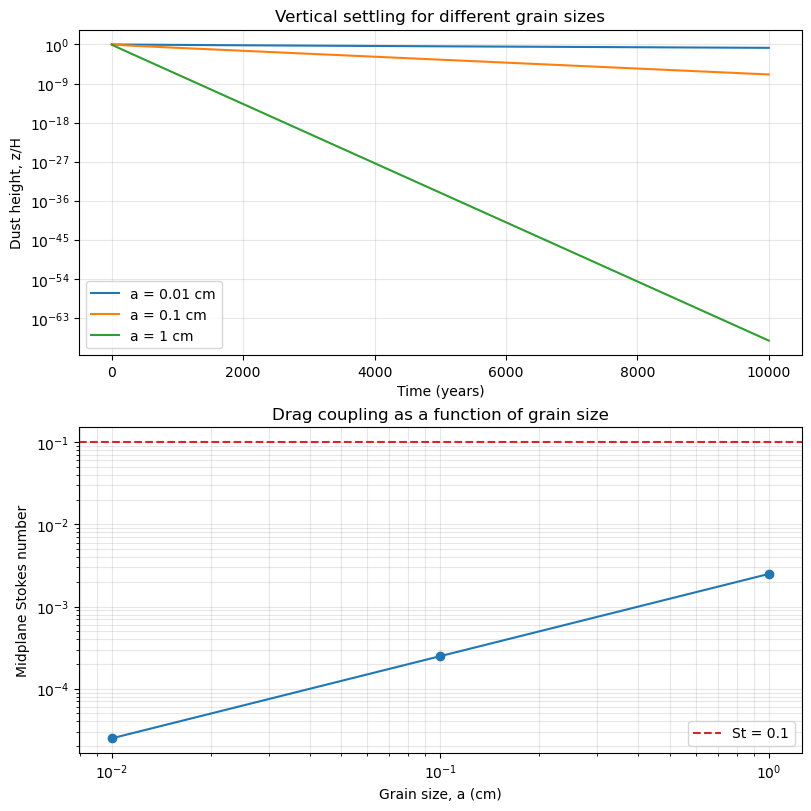

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(8, 8), constrained_layout=True)

for j, a in enumerate(grain_radii_cm):
    axes[0].semilogy(time_years, z_over_H[:, j], label=f"a = {a:g} cm")

axes[0].set(xlabel="Time (years)", ylabel="Dust height, z/H",
            title="Vertical settling for different grain sizes")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

stokes_midplane = rho_s * grain_radii_cm / (rho_mid * v_th) * Omega
axes[1].loglog(grain_radii_cm, stokes_midplane, "o-")
axes[1].axhline(0.1, color="tab:red", linestyle="--", label="St = 0.1")
axes[1].set(xlabel="Grain size, a (cm)", ylabel="Midplane Stokes number",
            title="Drag coupling as a function of grain size")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()

plt.show()

## Observations and further exploration

- Which grain size settles fastest? How is this reflected in the Stokes number?
- Try changing the `grain_radii_cm` array or the initial height `z0_over_H`, then rerun the notebook.
- The gas is less dense at greater heights, so the stopping time is longer there. As a grain moves downward, the denser gas couples to it more strongly.

This is an illustrative model. It does not include turbulent diffusion, radial gas or dust flow, grain growth, or dust feedback on the gas.